Analyze misclassified examples and their characteristics by manually clustering error cases, detecting anomalies in feature distributions, and performing root-cause analysis to determine if specific subgroups are disproportionately affected.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, brier_score_loss
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target])

X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100, max_depth=10,
        class_weight="balanced", random_state=42
    )
)

model.fit(X_train, y_train)

probabilities = model.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print(classification_report(y_test, predictions, zero_division=0))

Accuracy: 0.8125
              precision    recall  f1-score   support

           0       0.67      0.50      0.57         4
           1       0.85      0.92      0.88        12

    accuracy                           0.81        16
   macro avg       0.76      0.71      0.73        16
weighted avg       0.80      0.81      0.80        16



True Negatives: 2
False Positives: 2
False Negatives: 1
True Positives: 11


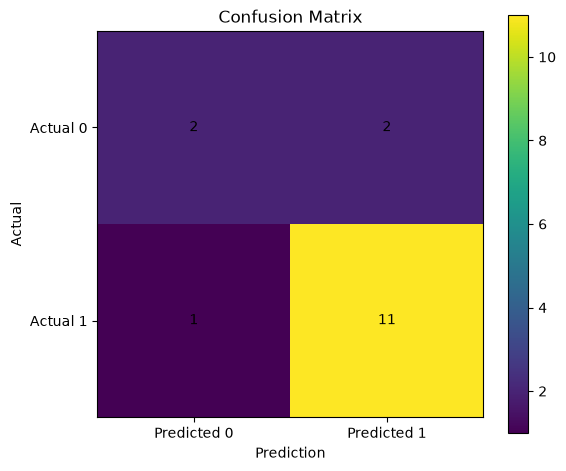

In [2]:
cm = confusion_matrix(y_test, predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.xticks([0, 1], ["Predicted 0", "Predicted 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

In [3]:
results = X_test.copy()
results["Actual"] = y_test
results["Predicted"] = predictions
results["Probability_Class_1"] = probabilities

false_positives = results[
    (results["Actual"] == 0) & (results["Predicted"] == 1)
]

false_negatives = results[
    (results["Actual"] == 1) & (results["Predicted"] == 0)
]

print("False Positive Examples:")
print(false_positives.to_string())

print("\nFalse Negative Examples:")
print(false_negatives.to_string())

False Positive Examples:
    age  trestbps  chol  thalach  oldpeak  Actual  Predicted  Probability_Class_1
36   68       191   232       91      1.5       0          1                 0.63
67   45       181   400      158      1.8       0          1                 0.97

False Negative Examples:
    age  trestbps  chol  thalach  oldpeak  Actual  Predicted  Probability_Class_1
47   36       156   163      109      0.5       1          0                  0.2



False Positives: 2
         age  trestbps    chol  thalach  oldpeak
count   2.00      2.00    2.00     2.00     2.00
mean   56.50    186.00  316.00   124.50     1.65
std    16.26      7.07  118.79    47.38     0.21
min    45.00    181.00  232.00    91.00     1.50
25%    50.75    183.50  274.00   107.75     1.58
50%    56.50    186.00  316.00   124.50     1.65
75%    62.25    188.50  358.00   141.25     1.72
max    68.00    191.00  400.00   158.00     1.80

False Negatives: 1
        age  trestbps   chol  thalach  oldpeak
count   1.0       1.0    1.0      1.0      1.0
mean   36.0     156.0  163.0    109.0      0.5
std     NaN       NaN    NaN      NaN      NaN
min    36.0     156.0  163.0    109.0      0.5
25%    36.0     156.0  163.0    109.0      0.5
50%    36.0     156.0  163.0    109.0      0.5
75%    36.0     156.0  163.0    109.0      0.5
max    36.0     156.0  163.0    109.0      0.5


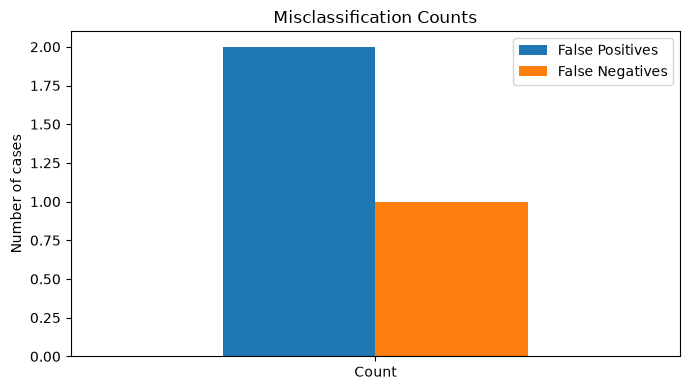

In [4]:
for name, errors in [
    ("False Positives", false_positives),
    ("False Negatives", false_negatives)
]:
    print(f"\n{name}: {len(errors)}")

    if len(errors) > 0:
        print(errors[features].describe().round(2))

error_counts = pd.DataFrame({
    "False Positives": [
        len(false_positives)
    ],
    "False Negatives": [
        len(false_negatives)
    ]
}, index=["Count"])

error_counts.plot(kind="bar", figsize=(7, 4), legend=True)
plt.title("Misclassification Counts")
plt.ylabel("Number of cases")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [5]:
X_train_part, X_val, y_train_part, y_val = train_test_split(
    X_train, y_train,
    test_size=0.25,
    random_state=21,
    stratify=y_train
)

threshold_model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        class_weight="balanced",
        random_state=42
    )
)

threshold_model.fit(X_train_part, y_train_part)
val_probabilities = threshold_model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in np.arange(0.2, 0.81, 0.05):
    val_predictions = (val_probabilities >= threshold).astype(int)
    tn_v, fp_v, fn_v, tp_v = confusion_matrix(
        y_val, val_predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "False Positives": fp_v,
        "False Negatives": fn_v,
        "Precision": tp_v / (tp_v + fp_v) if tp_v + fp_v else 0,
        "Recall": tp_v / (tp_v + fn_v) if tp_v + fn_v else 0
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df.to_string(index=False))

 Threshold  False Positives  False Negatives  Precision   Recall
      0.20                4                0   0.750000 1.000000
      0.25                4                0   0.750000 1.000000
      0.30                2                0   0.857143 1.000000
      0.35                2                0   0.857143 1.000000
      0.40                2                0   0.857143 1.000000
      0.45                2                2   0.833333 0.833333
      0.50                1                2   0.909091 0.833333
      0.55                1                2   0.909091 0.833333
      0.60                1                2   0.909091 0.833333
      0.65                1                3   0.900000 0.750000
      0.70                1                3   0.900000 0.750000
      0.75                1                4   0.888889 0.666667
      0.80                1                5   0.875000 0.583333


In [6]:
calibrated_model = CalibratedClassifierCV(
    estimator=make_pipeline(
        StandardScaler(),
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            class_weight="balanced",
            random_state=42
        )
    ),
    method="sigmoid",
    cv=3
)

calibrated_model.fit(X_train, y_train)

calibrated_probabilities = calibrated_model.predict_proba(X_test)[:, 1]

print("Original Brier score:",
      round(brier_score_loss(y_test, probabilities), 4))

print("Calibrated Brier score:",
      round(brier_score_loss(y_test, calibrated_probabilities), 4))

Original Brier score: 0.1688
Calibrated Brier score: 0.1722


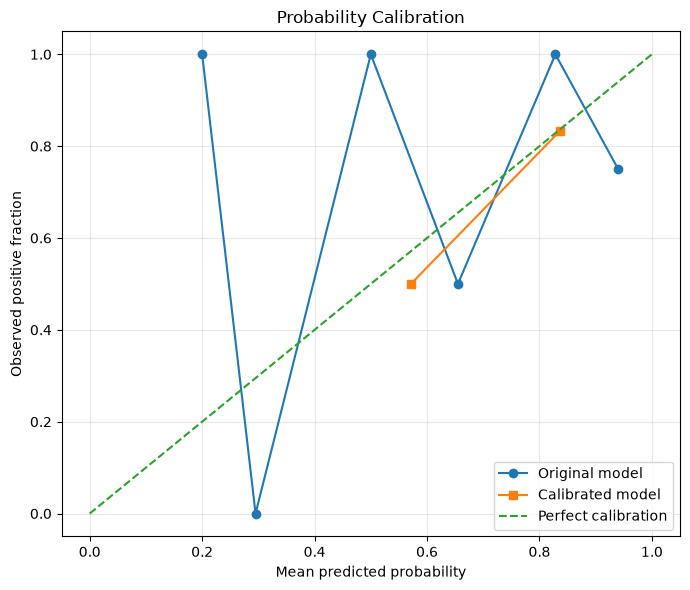

In [7]:
prob_original, mean_original = calibration_curve(
    y_test, probabilities, n_bins=8, strategy="uniform"
)

prob_calibrated, mean_calibrated = calibration_curve(
    y_test, calibrated_probabilities, n_bins=8, strategy="uniform"
)

plt.figure(figsize=(7, 6))
plt.plot(mean_original, prob_original, marker="o", label="Original model")
plt.plot(mean_calibrated, prob_calibrated, marker="s", label="Calibrated model")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive fraction")
plt.title("Probability Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()